# VS Code에서 .py와 .ipynb로 멀티 GPU 학습하기
커널: `./.venv/bin/python`

1. 환경 확인
2. 합성 데이터
3. 학습 (터미널)
4. 결과 분석

## 1. 환경 확인 (노드와 GPU)

In [2]:
!hostname; uname -m; nvidia-smi --query-gpu=index,name,memory.total --format=csv

node0065
aarch64
index, name, memory.total [MiB]
0, NVIDIA GH200 120GB, 97871 MiB
1, NVIDIA GH200 120GB, 97871 MiB
2, NVIDIA GH200 120GB, 97871 MiB
3, NVIDIA GH200 120GB, 97871 MiB


### `.venv`와 이미지
`.venv/bin/python`은 이미지의 `/usr/bin/python3.12`를 가리키는 링크다. 그래서 이 `.venv`는 이 이미지 안에서만 쓸 수 있다(호스트 python은 3.6).

In [3]:
import os, sys
from pathlib import Path
print("python :", sys.executable)
print("실제 실행 파일 :", os.path.realpath(sys.executable))
print("venv 사용 :", sys.prefix != sys.base_prefix, f"(prefix={sys.prefix})")

python : /scratch/optpar21/myksc-pytorch-ddp/.venv/bin/python
실제 실행 파일 : /usr/bin/python3.12
venv 사용 : True (prefix=/scratch/optpar21/myksc-pytorch-ddp/.venv)


In [4]:
import torch, pandas, matplotlib, seaborn, torchmetrics
for m in (torch, pandas, matplotlib, seaborn, torchmetrics):
    print(f"{m.__name__:11s} {m.__version__:30s} {os.path.dirname(m.__file__)}")
print("GPU:", torch.cuda.device_count(), "| PIP_CONSTRAINT =", os.environ.get("PIP_CONSTRAINT"))

torch       2.7.0a0+7c8ec84dab.nv25.03     /usr/local/lib/python3.12/dist-packages/torch
pandas      2.2.3                          /usr/local/lib/python3.12/dist-packages/pandas
matplotlib  3.10.1                         /usr/local/lib/python3.12/dist-packages/matplotlib
seaborn     0.13.2                         /scratch/optpar21/myksc-pytorch-ddp/.venv/lib/python3.12/site-packages/seaborn
torchmetrics 1.8.2                          /scratch/optpar21/myksc-pytorch-ddp/.venv/lib/python3.12/site-packages/torchmetrics
GPU: 4 | PIP_CONSTRAINT = /etc/pip/constraint.txt


torch, pandas, matplotlib은 이미지(`/usr/local/lib/python3.12/dist-packages`), seaborn과 torchmetrics는 `.venv`에서 온다.

torch 버전은 `PIP_CONSTRAINT`로 고정되어 있어서 `pip install`로 바뀌지 않는다.

### torchrun
`.venv/bin/torchrun`은 두 줄짜리 연결 파일이다. 이미지의 torchrun과 같은 코드(이미지 torch의 `torch.distributed.run`)를 실행하고, python만 `.venv`의 것으로 바꾼다.

torch·CUDA·NCCL은 그대로 이미지의 것을 쓰고, `.venv`에 설치한 패키지(torchmetrics 등)도 보이게 된다.

In [5]:
tr = Path(sys.prefix) / "bin" / "torchrun"
print(tr, "있음" if tr.exists() else "없음 -> 사용팁 '가상환경'의 printf 줄을 실행")
if tr.exists():
    print(tr.read_text())

/scratch/optpar21/myksc-pytorch-ddp/.venv/bin/torchrun 있음
#!/bin/sh
exec "$(dirname "$0")/python" -m torch.distributed.run "$@"



### 통신 설정
Slingshot 다중 노드용 값(`FI_CXI_*`, `NCCL_PROTO=^LL128`)은 이미지에 들어 있다.

In [6]:
for k in sorted(os.environ):
    if k.startswith(("FI_", "NCCL_")):
        print(f"{k:30s} = {os.environ[k]}")

FI_CXI_DEFAULT_CQ_SIZE         = 131072
FI_CXI_DEFAULT_TX_SIZE         = 2048
FI_CXI_DISABLE_HOST_REGISTER   = 1
FI_CXI_RDZV_EAGER_SIZE         = 0
FI_CXI_RDZV_GET_MIN            = 0
FI_CXI_RDZV_PROTO              = alt_read
FI_CXI_RDZV_THRESHOLD          = 0
FI_CXI_RX_MATCH_MODE           = hybrid
FI_MR_CACHE_MONITOR            = userfaultfd
NCCL_NET                       = AWS Libfabric
NCCL_NET_PLUGIN                = /opt/kisti/slingshot/nccl-plugin/libnccl-net-ofi.so
NCCL_PROTO                     = ^LL128
NCCL_VERSION                   = 2.25.1


`NCCL_NET=AWS Libfabric`은 Slingshot을 쓰는 설정이다. VS Code 터미널에서는 Slingshot을 쓸 수 없어서 1노드 학습 때 이 값을 끈다.

## 2. 합성 데이터
`y = f(x) + noise` (noise 표준편차 0.1). 모델이 `f(x)`를 배우면 val loss가 0.01 근처까지 내려간다.

- train 400만 개: 학습에 사용
- val 10만 개: 학습에 쓰지 않고, 에폭마다 처음 보는 데이터에서 성능 확인

학습 스크립트는 여기서 저장한 `data/synthetic.npz`를 읽는다.

### 생성

In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

rng = np.random.default_rng(0)
NOISE = 0.1

def f(x):
    return np.sin(2 * np.pi * x) + 0.5 * np.sin(5 * np.pi * x) * np.exp(-x**2)

def make(n):
    x = rng.uniform(-1, 1, size=(n, 1)).astype(np.float32)
    y = (f(x) + NOISE * rng.standard_normal((n, 1))).astype(np.float32)
    return x, y

x_train, y_train = make(4_000_000)
x_val, y_val = make(100_000)
x_grid = np.linspace(-1, 1, 1001, dtype=np.float32).reshape(-1, 1)
y_grid = f(x_grid).astype(np.float32)          # 노이즈 없는 f(x), 그림용
print(f"train (학습용): x {x_train.shape}, y {y_train.shape}")
print(f"val   (검증용): x {x_val.shape}, y {y_val.shape}")

train (학습용): x (4000000, 1), y (4000000, 1)
val   (검증용): x (100000, 1), y (100000, 1)


### 분포

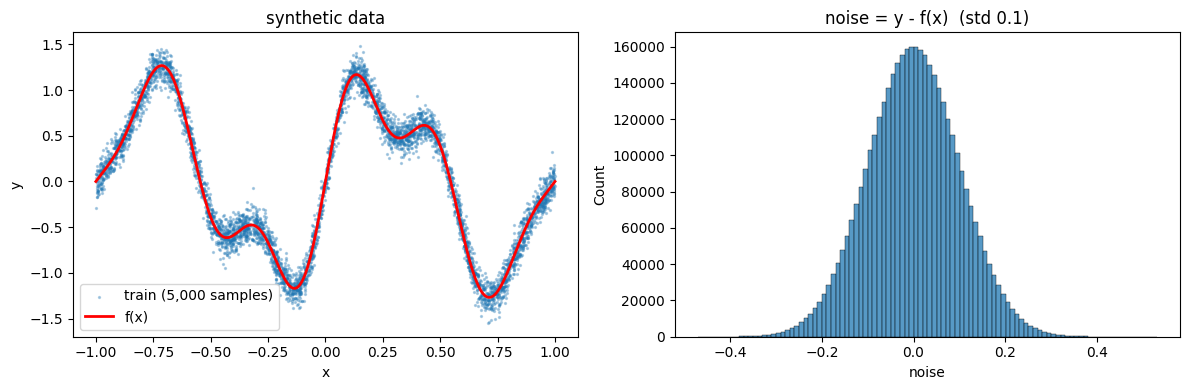

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
idx = rng.choice(len(x_train), 5000, replace=False)
ax[0].scatter(x_train[idx], y_train[idx], s=2, alpha=0.3, label="train (5,000 samples)")
ax[0].plot(x_grid, y_grid, "r", lw=2, label="f(x)")
ax[0].set(xlabel="x", ylabel="y", title="synthetic data"); ax[0].legend()
sns.histplot((y_train - f(x_train))[:, 0], bins=100, ax=ax[1])
ax[1].set(title=f"noise = y - f(x)  (std {NOISE})", xlabel="noise")
plt.tight_layout()

### 저장

In [9]:
Path("data").mkdir(exist_ok=True)
np.savez("data/synthetic.npz", x_train=x_train, y_train=y_train, x_val=x_val, y_val=y_val)
print(f"data/synthetic.npz  {Path('data/synthetic.npz').stat().st_size / 2**20:.1f} MiB")

data/synthetic.npz  31.3 MiB


## 3. 학습 (터미널)
GPU마다 프로세스를 하나씩 띄워야 해서, 학습은 `.ipynb`가 아니라 터미널에서 돌린다.

### 모델 확인
`train_ddp.py`의 `build_model`을 그대로 불러온다. `%autoreload 2`라서 `.py`를 고치고 이 셀만 다시 실행하면 된다.

In [10]:
%load_ext autoreload
%autoreload 2
from train_ddp import build_model
m = build_model()
print(m)
print(f"{sum(p.numel() for p in m.parameters()) / 1e6:.1f}M params")

Sequential(
  (0): Linear(in_features=1, out_features=2048, bias=True)
  (1): SiLU()
  (2): Linear(in_features=2048, out_features=2048, bias=True)
  (3): SiLU()
  (4): Linear(in_features=2048, out_features=2048, bias=True)
  (5): SiLU()
  (6): Linear(in_features=2048, out_features=2048, bias=True)
  (7): SiLU()
  (8): Linear(in_features=2048, out_features=2048, bias=True)
  (9): SiLU()
  (10): Linear(in_features=2048, out_features=2048, bias=True)
  (11): SiLU()
  (12): Linear(in_features=2048, out_features=1, bias=True)
)
21.0M params


### DistributedSampler
4GPU일 때 rank마다 받는 데이터를 확인한다. 1/4씩, 서로 겹치지 않는다.

In [11]:
from torch.utils.data import DistributedSampler
n, world = len(x_train), 4
parts = [set(DistributedSampler(range(n), num_replicas=world, rank=r)) for r in range(world)]
for r, s in enumerate(parts):
    print(f"rank {r}: {len(s):,}개, 앞 5개 {sorted(s)[:5]}")
total = sum(map(len, parts))
print("겹치는 샘플:", total - len(set.union(*parts)), "| 합계:", total)

rank 0: 1,000,000개, 앞 5개 [2, 6, 9, 12, 21]
rank 1: 1,000,000개, 앞 5개 [8, 14, 15, 16, 17]
rank 2: 1,000,000개, 앞 5개 [0, 1, 3, 4, 5]
rank 3: 1,000,000개, 앞 5개 [18, 20, 24, 25, 29]
겹치는 샘플: 0 | 합계: 4000000


### 1노드 4GPU
VS Code 터미널에서:
```bash
cd /scratch/$USER/myksc-pytorch-ddp
source .venv/bin/activate
export NCCL_NET_PLUGIN=none NCCL_NET=Socket     # Slingshot 비활성화 (VS Code 터미널에서 사용 불가)
torchrun --standalone --nproc-per-node=4 train_ddp.py
```

### 2노드 8GPU
앱을 2노드로 열고, 호스트 셸에서:
```bash
ssh $(hostname)
cd /scratch/$USER/myksc-pytorch-ddp
bash run_2node.sh
exit
```

전체 배치(`--global-batch`)는 GPU 수와 상관없이 같고, GPU당 배치는 전체 / GPU 수다. 그래서 두 실행은 같은 학습을 하고, 걸리는 시간만 다르다.

## 4. 결과 분석
`runs/*/metrics.csv`를 읽는다.

### 요약

In [1]:
import glob
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns

df = pd.concat([pd.read_csv(p).assign(run=Path(p).parent.name)
                for p in sorted(glob.glob("runs/*/metrics.csv"))], ignore_index=True)
df[df.epoch > 0].groupby("run").agg(gpus=("gpus", "first"), final_val=("val_loss", "last"),
                                    epoch_time_s=("epoch_time_s", "mean")).round(4)

,gpus,final_val,epoch_time_s
run,,,
4gpu,4,0.01,1.0481
8gpu,8,0.01,0.8806


### 같은 학습, 다른 시간

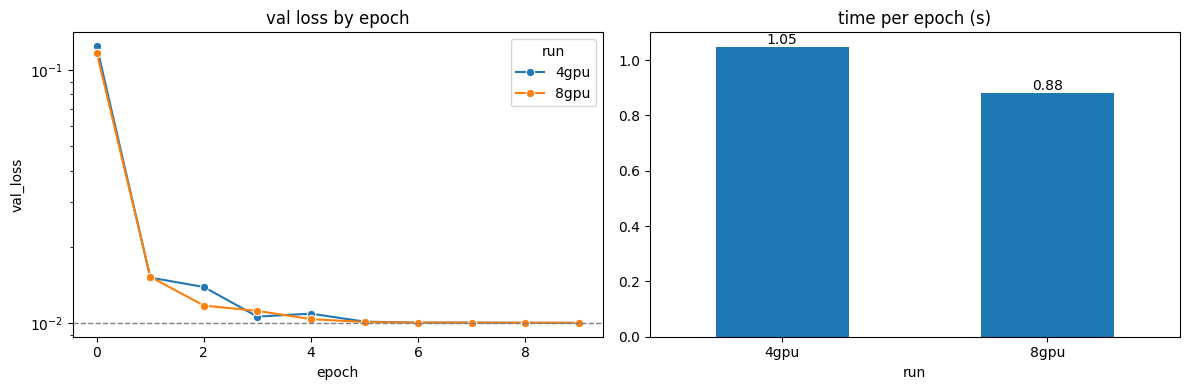

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(df, x="epoch", y="val_loss", hue="run", marker="o", ax=ax[0])
ax[0].set_yscale("log"); ax[0].axhline(0.01, color="gray", ls="--", lw=1); ax[0].set_title("val loss by epoch")
t = df[df.epoch > 0].groupby("run")["epoch_time_s"].mean()   # epoch 0(초기화 포함) 제외
t.plot.bar(ax=ax[1], rot=0, title="time per epoch (s)")
for i, v in enumerate(t):
    ax[1].text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.tight_layout()

- 왼쪽 그림(에폭별 val loss): 두 곡선이 거의 겹친다. 같은 학습을 했다는 뜻이다.
- 오른쪽 그림(에폭당 시간): 8GPU가 더 짧다. 첫 에폭은 통신 연결 같은 초기화가 들어가서 뺐다.

2배가 아닌 이유: 스텝마다 기울기를 노드 사이로 주고받는 시간이 붙는다. 모델이 작아 GPU 계산이 짧을수록 이 비율이 크다.